In [1]:
# ruff: noqa: E402

# Neural Book Recommender: dari Embedding sampai Pembaruan Adam

**Model neural menjadi pusat pembelajaran proyek ini.** Dengan interaksi
pengguna–buku–rating dari Book-Crossing, kita memperlihatkan lima konsep dalam
satu proses nyata: **embedding, forward propagation, loss function,
backpropagation, dan optimisasi**. Model menggabungkan embedding dengan beberapa
hidden layer sehingga interaksi dipelajari melalui jaringan neural.

Notebook `01_end_to_end_book_recommender.ipynb` tetap menjadi pembanding untuk
popularity, item-based, content-based, dan hybrid. Keberadaan neural network
belum membuktikan bahwa rekomendasinya lebih baik. Kita menguji prediksi rating
dan ranking pada data yang ditahan, lalu membandingkan ranking dengan baseline.

Persiapan: jalankan `uv sync --extra neural --dev`, unduh `Books.csv`,
`Ratings.csv`, dan `Users.csv` ke `data/raw`, kemudian jalankan seluruh cell.
Angka dan tabel di bawah dihasilkan saat notebook dijalankan; tidak ada angka
performa yang diisi terlebih dahulu.

## Persiapan opsional di Google Colab GPU

Pilih **Runtime → Change runtime type → GPU**. Upload source ZIP yang berisi
perubahan neural ini, ekstrak sehingga checkout berada di
`/content/System-Recommendation`, lalu instal dengan:

```python
from google.colab import files
import shutil
files.upload()  # pilih book-recommender-neural-source.zip
shutil.unpack_archive("/content/book-recommender-neural-source.zip", "/content")
%pip install "/content/System-Recommendation[neural]"
%cd /content/System-Recommendation
```

Source lokal belum tentu sudah tersedia di branch `main` GitHub. Gunakan ZIP
perubahan ini; clone GitHub hanya setelah commit/branch neural tersedia.
Dataset publik dapat diunduh dalam cell setup berikut, tanpa menyalin CSV
besar dari laptop:

```python
from urllib.request import urlretrieve
from zipfile import ZipFile
urlretrieve(
    "https://www.kaggle.com/api/v1/datasets/download/arashnic/book-recommendation-dataset",
    "/content/book-crossing.zip",
)
with ZipFile("/content/book-crossing.zip") as archive:
    for name in ("Books.csv", "Ratings.csv", "Users.csv"):
        archive.extract(name, "/content/System-Recommendation/data/raw")
```

Jika endpoint meminta autentikasi, gunakan Kaggle CLI atau upload tiga CSV
dataset ke `/content/System-Recommendation/data/raw` (lihat README).
Kemudian upload/buka notebook ini di Colab dan jalankan seluruh cell. Cell
berikut menampilkan perangkat GPU yang benar-benar terdeteksi. TensorFlow
otomatis menempatkan operasi yang didukung pada GPU; CPU tetap diperlukan
untuk cleaning dan evaluasi. Ukuran model kecil dapat membuat biaya transfer
lebih besar daripada percepatan GPU, jadi percepatan perlu diukur.

Untuk eksekusi melalui Colab CLI dari direktori `/content`, set
`BOOK_RECOMMENDER_PROJECT_ROOT` ke checkout yang telah diupload, misalnya
`/content/book-recommendation-neural-20261013/System-Recommendation`.
Direktori data dapat diset terpisah dengan `BOOK_RECOMMENDER_DATA_DIR`.
Workflow CLI memakai helper dan session proyek tersendiri; lihat README untuk
OAuth2, monitoring checkpoint, verifikasi download, dan penghentian runtime.

In [2]:
from __future__ import annotations

import os

# Tetapkan batas thread SEBELUM mengimpor TensorFlow, NumPy, dan scikit-learn.
for variable in (
    "OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS",
    "NUMEXPR_NUM_THREADS", "TF_NUM_INTRAOP_THREADS", "TF_NUM_INTEROP_THREADS",
):
    os.environ[variable] = "1"
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

from pathlib import Path
from time import perf_counter

import matplotlib

try:
    get_ipython
except NameError:
    matplotlib.use("Agg")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import Markdown, display

from book_recommender.collaborative import ItemBasedCollaborativeRecommender
from book_recommender.content_based import book_work_key
from book_recommender.data import dataset_summary, load_clean_dataset
from book_recommender.evaluation import prepare_validation_test_evaluation, ranking_metrics_at_k
from book_recommender.neural import NeuralRecommender

pd.set_option("display.max_columns", 25)
pd.set_option("display.max_colwidth", 85)


def find_project_root(start: Path) -> Path:
    configured_root = os.environ.get("BOOK_RECOMMENDER_PROJECT_ROOT")
    if configured_root:
        candidate = Path(configured_root).expanduser().resolve()
        if not (candidate / "pyproject.toml").is_file():
            raise FileNotFoundError(
                f"BOOK_RECOMMENDER_PROJECT_ROOT tidak menunjuk checkout proyek: {candidate}"
            )
        return candidate
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Jalankan notebook dari checkout proyek ini.")


PROJECT_ROOT = find_project_root(Path.cwd())
DATA_DIR = Path(os.environ.get("BOOK_RECOMMENDER_DATA_DIR", "data/raw"))
if not DATA_DIR.is_absolute():
    DATA_DIR = PROJECT_ROOT / DATA_DIR
MAX_BOOKS = int(os.environ.get("BOOK_RECOMMENDER_NOTEBOOK_MAX_BOOKS", "5000"))
SAMPLE_USERS = int(os.environ.get("BOOK_RECOMMENDER_NOTEBOOK_EVAL_USERS", "100"))
EPOCHS = int(os.environ.get("BOOK_RECOMMENDER_NEURAL_EPOCHS", "5"))
TOP_K = 10
RANDOM_STATE = 42
EMBEDDING_SIZE = 16
HIDDEN_UNITS = (32, 16)
LEARNING_RATE = 0.001
L2 = 1e-5
IS_SYNTHETIC_FIXTURE = "fixtures" in DATA_DIR.parts
RESULT_LABEL = (
    "SYNTHETIC FIXTURE — hanya smoke test" if IS_SYNTHETIC_FIXTURE
    else os.environ.get("BOOK_RECOMMENDER_DATA_LABEL", "Book-Crossing")
)
display(Markdown(f"**Sumber eksekusi: {RESULT_LABEL}.** Direktori: `{DATA_DIR}`."))
display(pd.Series({
    "tensorflow": tf.__version__, "maksimum_buku_train": MAX_BOOKS,
    "user_holdout_diminta": SAMPLE_USERS, "maksimum_epoch": EPOCHS,
    "embedding_size": EMBEDDING_SIZE, "hidden_units": HIDDEN_UNITS,
    "learning_rate": LEARNING_RATE, "l2": L2, "random_state": RANDOM_STATE,
}, name="konfigurasi"))
display(pd.Series({
    "GPU_terdeteksi": [device.name for device in tf.config.list_physical_devices("GPU")],
}, name="perangkat_tensorflow"))

**Sumber eksekusi: Book-Crossing — subset 5.000 ISBN metadata hash; smoke test GPU T4.** Direktori: `/content/book-recommendation-neural-20261014-residual/neural-smoke-data`.

,konfigurasi
tensorflow,2.21.0
maksimum_buku_train,5000
user_holdout_diminta,100
maksimum_epoch,5
embedding_size,16
hidden_units,"(32, 16)"
learning_rate,0.001
l2,0.00001
random_state,42


,perangkat_tensorflow
GPU_terdeteksi,[/physical_device:GPU:0]


## 1. Data mendukung pembelajaran embedding

Satu baris explicit feedback menyediakan ID pengguna, ISBN, dan rating. ID
diubah menjadi indeks embedding; rating menjadi target yang ingin diprediksi.
`load_clean_dataset` menggunakan cleaning produksi: rating 0 dikeluarkan karena
merupakan interaksi implisit, duplikat user–ISBN dirata-ratakan, dan rating
tanpa metadata buku dikeluarkan. Rating eksplisit berada pada skala 1–10.

Sparsity membatasi kualitas parameter yang dapat dipelajari; hal ini kita
tangani dengan minimum interaksi, regularisasi, validation, dan fallback.
Sparsity tidak menghalangi demonstrasi kelima konsep training.

In [3]:
clean_dataset = load_clean_dataset(DATA_DIR)
display(pd.Series(dataset_summary(clean_dataset), name="data_setelah_cleaning"))
display(clean_dataset.ratings.head().merge(
    clean_dataset.books[["isbn", "book_title", "book_author"]], on="isbn",
))

,data_setelah_cleaning
books,5000
ratings,6925
users,7995
rated_books,2714
rating_users,4616


,user_id,isbn,book_rating,book_title,book_author
0,276748,0747558167,6.0,Apricots on the Nile: A Memoir with Recipes,Colette Rossant
1,276847,3821815191,10.0,Das bizarre Sexualleben der Tiere. Ein populÃ?Â¤res Lexikon von Aal bis Zebra.,Michael Miersch
2,276925,8426109799,8.0,Los Cinco Van De Camping/the Five on the Track of a Spook Train,Enid Blyton
3,276939,2253137243,9.0,Le Jour des fourmis,Bernard Werber
4,276988,0671793489,8.0,All Around the Town,Mary Higgins Clark


## 2. Pisahkan data sebelum memilih katalog dan membangun vocabulary

Kita menahan satu karya yang memiliki rating eksplisit untuk setiap pengguna
yang memenuhi
syarat, lalu membagi pengguna holdout menjadi kelompok validation dan test
yang berbeda. Seluruh ISBN dari karya yang ditahan dihapus dari histori
training pengguna tersebut. Buku yang sama tetap boleh mendapat rating dari
pengguna lain: itulah sinyal collaborative yang sah.

K-core (minimum dua rating per pengguna dan per ISBN) serta pemilihan maksimal
5.000 buku hanya membaca train split. Vocabulary embedding juga hanya membaca
train. Model tidak mendapat embedding terlatih untuk user atau ISBN yang baru
muncul pada validation/test. Metadata target tidak dipakai sebagai fitur model.

Validation dipakai untuk early stopping. Test baru dievaluasi setelah training
selesai, tanpa mengganti konfigurasi berdasarkan hasil test.

In [4]:
evaluation = prepare_validation_test_evaluation(
    clean_dataset,
    sample_users=SAMPLE_USERS,
    validation_fraction=0.5,
    min_interactions=3,
    min_relevant_rating=1.0,
    min_user_ratings=2,
    min_book_ratings=2,
    max_books=MAX_BOOKS,
    random_state=RANDOM_STATE,
)
train_ratings = evaluation.train_dataset.ratings
# Semua model pembanding mendapat katalog kandidat ISBN train yang sama.
train_books = evaluation.train_dataset.books[
    evaluation.train_dataset.books.isbn.isin(train_ratings.isbn)
].reset_index(drop=True)
validation_ratings = evaluation.validation_holdout_ratings
test_ratings = evaluation.test_holdout_ratings
if train_ratings.empty:
    raise ValueError("Train kosong setelah filtering. Periksa dataset dan batas katalog.")
isbn_to_work = {
    str(row.isbn): book_work_key(row.book_title, row.book_author, row.isbn)
    for row in clean_dataset.books.itertuples(index=False)
}
training_work_pairs = {
    (int(row.user_id), isbn_to_work[str(row.isbn)])
    for row in train_ratings.itertuples(index=False)
}
assert set(validation_ratings.user_id).isdisjoint(test_ratings.user_id)
for holdouts in (validation_ratings, test_ratings):
    assert all(
        (int(row.user_id), str(row.work_key)) not in training_work_pairs
        for row in holdouts.itertuples(index=False)
    ), "Holdout karya pengguna masih muncul dalam training."
display(pd.DataFrame([
    {"split": "train", "pasangan": len(train_ratings),
     "user": train_ratings.user_id.nunique(), "isbn": train_ratings.isbn.nunique()},
    {"split": "validation", "pasangan": len(validation_ratings),
     "user": validation_ratings.user_id.nunique(), "isbn": validation_ratings.isbn.nunique()},
    {"split": "test", "pasangan": len(test_ratings),
     "user": test_ratings.user_id.nunique(), "isbn": test_ratings.isbn.nunique()},
]))

,split,pasangan,user,isbn
0,train,1622,545,401
1,validation,50,50,50
2,test,50,50,49


## 3. Embedding: parameter yang dipelajari untuk pengguna dan buku

`NeuralRecommender.initialize` membangun jaringan tanpa training. Matriks
embedding pengguna berukuran `jumlah_user_train × 16`; matriks buku berukuran
`jumlah_isbn_train × 16`. Nilai awal acak belum bermakna. Setiap dimensinya
merupakan latent feature, bukan label eksplisit seperti genre atau usia.

Kita menggunakan objek **demo terpisah** untuk satu langkah training. Setelah
demonstrasi, eksperimen penuh membuat model baru. Pembaruan demo tidak ikut
menyumbang training atau evaluasi model akhir.

In [5]:
demo = NeuralRecommender(
    embedding_size=EMBEDDING_SIZE, hidden_units=HIDDEN_UNITS,
    learning_rate=LEARNING_RATE, l2=L2, random_state=RANDOM_STATE,
).initialize(train_books, train_ratings)
batch = train_ratings.head(8).copy()
pairs, targets, unknown = demo.encode_ratings(batch)
assert unknown == 0
display(pd.DataFrame({
    "user_id": batch.user_id, "isbn": batch.isbn,
    "index_user": pairs[:, 0], "index_buku": pairs[:, 1],
    "rating_asli": batch.book_rating,
    "target_normalisasi": targets[:, 0],
}))
display(pd.DataFrame({
    "embedding": ["pengguna", "buku"],
    "shape": [tuple(demo.model.user_embedding.embeddings.shape),
              tuple(demo.model.book_embedding.embeddings.shape)],
}))
demo.model.summary()

,user_id,isbn,index_user,index_buku,rating_asli,target_normalisasi
0,277427,0061009059,541,18,9.0,0.888889
1,277427,0425190749,541,157,7.0,0.666667
2,277929,0451198948,542,203,8.0,0.777778
3,277929,0553561537,542,248,9.0,0.888889
4,278026,0061009059,543,18,8.0,0.777778
5,278026,0671001795,543,264,8.0,0.777778
6,278582,0449217213,544,190,8.0,0.777778
7,278582,0451202503,544,204,10.0,1.000000


,embedding,shape
0,pengguna,"(545, 16)"
1,buku,"(401, 16)"


Model: "neural_rating_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ user_embedding (Embedding)      │ (1, 16)                │         8,720 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ book_embedding (Embedding)      │ (1, 16)                │         6,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_1 (Dense)                │ (1, 32)                │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (1, 16)                │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rating (Dense)                  │ (1, 1)                 │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,249 (67.38 KB)

 Trainable params: 17,249 (67.38 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Forward propagation: dari dua vektor menuju prediksi rating

Untuk satu pasangan pengguna–buku, model mengambil `u` dan `v`, lalu membentuk
`x = concat(u, v, u * v)`. Produk elemen demi elemen memberi sinyal interaksi.
Dua layer Dense (32 dan 16 unit, aktivasi ReLU) menghasilkan representasi
nonlinear. Dense terakhir dengan sigmoid menghasilkan nilai pada 0–1.

Target dinormalisasi dengan `(rating − 1) / 9`. Untuk interpretasi kita
mengembalikan prediksi ke skala rating: `rating_prediksi = 1 + 9 * output`.
Semua operasi berlangsung per pasangan; tidak ada pencampuran pengguna
antarbaris batch.

In [6]:
pair_tensor = tf.convert_to_tensor(pairs, dtype=tf.int32)
user_vectors = demo.model.user_embedding(pair_tensor[:, 0])
book_vectors = demo.model.book_embedding(pair_tensor[:, 1])
activations = tf.concat([user_vectors, book_vectors, user_vectors * book_vectors], axis=1)
activation_shapes = [{"tahap": "concat(u, v, u*v)", "shape": tuple(activations.shape)}]
for layer in demo.model.hidden:
    activations = layer(activations)
    activation_shapes.append({"tahap": layer.name, "shape": tuple(activations.shape)})
manual_predictions = demo.model.output_layer(activations)
forward_predictions = demo.model(pair_tensor, training=False)
np.testing.assert_allclose(manual_predictions.numpy(), forward_predictions.numpy(), atol=1e-7)
display(pd.DataFrame(activation_shapes))
display(pd.DataFrame({
    "rating_asli": batch.book_rating.to_numpy(),
    "output_sigmoid": forward_predictions.numpy().ravel(),
    "rating_prediksi_sebelum_training": 1 + 9 * forward_predictions.numpy().ravel(),
}))

,tahap,shape
0,"concat(u, v, u*v)","(8, 48)"
1,hidden_1,"(8, 32)"
2,hidden_2,"(8, 16)"


,rating_asli,output_sigmoid,rating_prediksi_sebelum_training
0,9.0,0.492656,5.433901
1,7.0,0.495872,5.462846
2,8.0,0.501463,5.513168
3,9.0,0.498470,5.486231
4,8.0,0.496867,5.471801
5,8.0,0.503934,5.535406
6,8.0,0.499241,5.493165
7,10.0,0.498860,5.489741


## 5. Loss function dan backpropagation melalui `tf.GradientTape`

Loss yang diminimalkan adalah `mean((target − prediksi)²) + L2`.
MSE mengukur kesalahan prediksi rating yang sudah dinormalisasi; L2 memberi
penalti pada besarnya embedding dan kernel Dense. MSE dan regularisasi
ditampilkan terpisah supaya arti loss terlihat jelas.

`GradientTape` merekam operasi forward dan loss. `tape.gradient` menerapkan
chain rule untuk menghitung turunan terhadap seluruh parameter terlatih.
Gradien memberitahu seberapa sensitif loss terhadap perubahan parameter.
Adam kemudian memakai gradien tersebut untuk melakukan pembaruan.

Cell berikut menampilkan operasi yang juga dipakai oleh
`NeuralRecommender.loss_and_gradients`; jadi backpropagation tidak tersembunyi
hanya di dalam `model.fit()`. Penghitungan ini belum memperbarui parameter.

In [7]:
with tf.GradientTape() as tape:
    predictions = demo.model(pair_tensor, training=True)
    mse = tf.reduce_mean(tf.square(tf.cast(targets, tf.float32) - predictions))
    regularization = tf.add_n(demo.model.losses)
    total_loss = mse + regularization
gradients = tape.gradient(total_loss, demo.model.trainable_variables)
display(pd.Series({
    "MSE_normalisasi": float(mse.numpy()),
    "penalti_L2": float(regularization.numpy()),
    "loss_total": float(total_loss.numpy()),
}, name="loss_batch_sebelum_update"))
display(pd.DataFrame([
    {"parameter": variable.path, "shape": tuple(variable.shape),
     "norm_gradien": float(tf.linalg.global_norm([gradient]).numpy())}
    for variable, gradient in zip(demo.model.trainable_variables, gradients)
]))
assert all(gradient is not None for gradient in gradients)
assert all(np.isfinite(float(tf.linalg.global_norm([gradient]).numpy())) for gradient in gradients)

,loss_batch_sebelum_update
MSE_normalisasi,0.112197
penalti_L2,0.000720
loss_total,0.112917


,parameter,shape,norm_gradien
0,neural_rating_model/user_embedding/embeddings,"(545, 16)",0.039818
1,neural_rating_model/book_embedding/embeddings,"(401, 16)",0.030884
2,neural_rating_model/hidden_1/kernel,"(48, 32)",0.009899
3,neural_rating_model/hidden_1/bias,"(32,)",0.090014
4,neural_rating_model/hidden_2/kernel,"(32, 16)",0.013111
5,neural_rating_model/hidden_2/bias,"(16,)",0.161964
6,neural_rating_model/rating/kernel,"(16, 1)",0.007695
7,neural_rating_model/rating/bias,"(1,)",0.160504


## 6. Optimisasi Adam: lihat parameter sebelum dan sesudah

`trace_training_step` mengulangi forward dan backpropagation pada batch yang
sama, lalu menjalankan satu pembaruan yang sesungguhnya:
`optimizer.apply_gradients(zip(gradients, model.trainable_variables))`.

Adam menyimpan estimasi momen pertama dan kedua gradien untuk menyesuaikan
pembaruan tiap parameter. Karena itu, delta embedding bukan sekadar
`−learning_rate × gradien` seperti SGD biasa. Grafik menunjukkan satu baris
embedding pengguna pertama di batch. Satu langkah tidak menjamin penurunan
loss untuk setiap batch berikutnya, apalagi performa pada data test.

,satu_langkah_training_demo
optimizer,Adam
optimizer_iterations,1
mse_before,0.112197
regularization_loss,0.00072
total_loss_before,0.112917
mse_after,0.1103
embedding_delta_norm,0.003989


,sebelum,gradien,sesudah,delta
dimensi_latent,,,,
0,-0.025317,0.006465,-0.026316,-0.001000
1,0.038367,-0.002639,0.039366,0.000999
2,0.001210,-0.001037,0.002207,0.000997
3,0.005958,0.002199,0.004959,-0.000999
4,0.043837,0.003939,0.042838,-0.000999
5,0.006292,-0.006495,0.007291,0.001000
6,0.034024,0.001916,0.033025,-0.000998
7,0.019293,0.001683,0.018295,-0.000998
8,-0.036572,-0.004271,-0.035573,0.000999


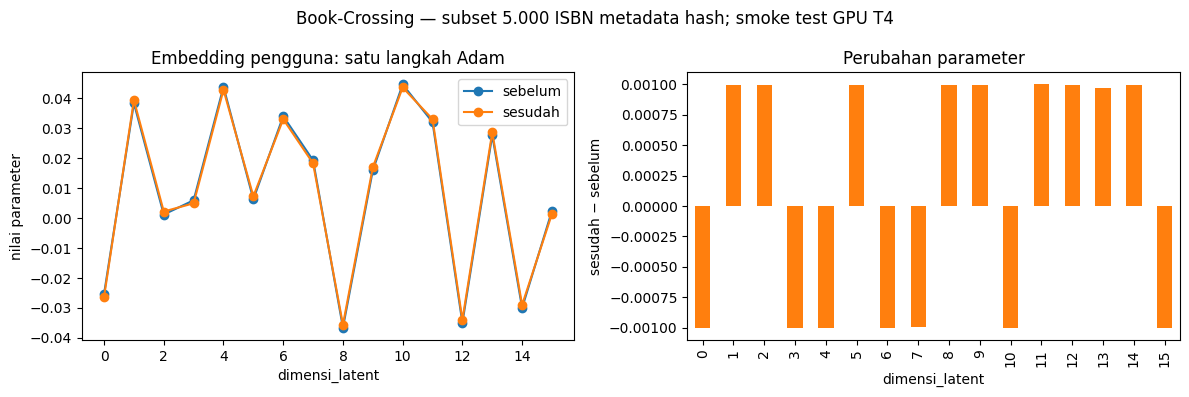

In [8]:
trace = demo.trace_training_step(pairs, targets)
display(pd.Series({key: trace[key] for key in (
    "optimizer", "optimizer_iterations", "mse_before", "regularization_loss",
    "total_loss_before", "mse_after", "embedding_delta_norm",
)}, name="satu_langkah_training_demo"))
embedding_change = pd.DataFrame({
    "sebelum": trace["user_embedding_before"],
    "gradien": trace["user_embedding_gradient"],
    "sesudah": trace["user_embedding_after"],
})
embedding_change["delta"] = embedding_change.sesudah - embedding_change.sebelum
embedding_change.index.name = "dimensi_latent"
display(embedding_change)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
embedding_change[["sebelum", "sesudah"]].plot(marker="o", ax=axes[0])
axes[0].set(title="Embedding pengguna: satu langkah Adam", ylabel="nilai parameter")
embedding_change["delta"].plot.bar(ax=axes[1], color="tab:orange")
axes[1].set(title="Perubahan parameter", ylabel="sesudah − sebelum")
fig.suptitle(RESULT_LABEL)
plt.tight_layout()
plt.show()
assert trace["optimizer_iterations"] == 1
assert trace["embedding_delta_norm"] > 0

## 7. Training nyata dengan early stopping pada validation

Model baru mengulangi mini-batch training menggunakan Adam. Validation MSE
dihitung pada pasangan user dan ISBN yang dikenal dari training. Ketika
validation tidak membaik selama tiga epoch, training dihentikan; bobot dari
epoch dengan validation MSE terbaik dikembalikan. Riwayat train/validation
di bawah tidak mencakup penalti L2, sehingga keduanya dapat dibandingkan.

Validation dan test mempertahankan target rating 1–10; pemilihan holdout tidak
hanya mengambil rating positif. Unknown pair dihitung dan dilaporkan, lalu dikeluarkan
dari RMSE karena embedding-nya belum dipelajari. Unknown pair tetap dihitung
dalam evaluasi ranking end-to-end pada bagian berikutnya.

,ketersediaan_validation_sebelum_training
explicit_pairs,50
known_pairs,11
unknown_pairs,39
mse_normalized,0.096616
rmse_rating_scale,2.797487
scope,known_user_and_book_pairs_only


,epoch,train_mse,train_rmse,val_mse,val_rmse
0,1,0.101403,2.865949,0.091869,2.727891
1,2,0.094213,2.762479,0.085774,2.635840
2,3,0.086096,2.640793,0.078794,2.526330
3,4,0.076723,2.492910,0.070674,2.392605
4,5,0.065958,2.311405,0.061476,2.231485


,ringkasan_training
durasi_training_detik,1.553792
epoch_terbaik_validation,5.000000
epoch_dijalankan,5.000000
user_vocabulary_train,545.000000
isbn_vocabulary_train,401.000000


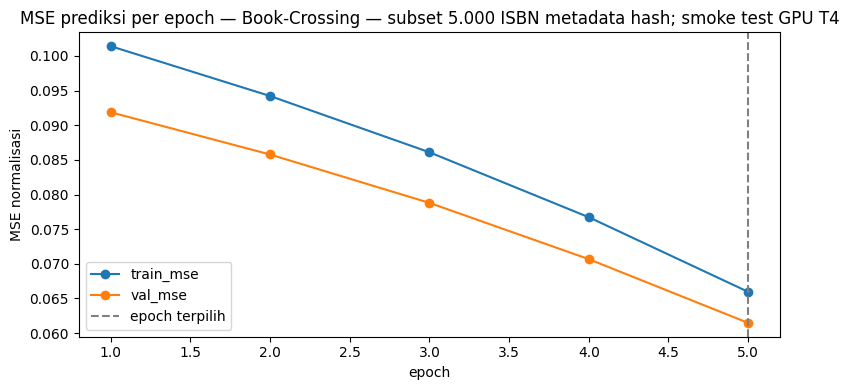

In [9]:
validation_coverage = demo.evaluate_ratings(validation_ratings)
display(pd.Series(validation_coverage, name="ketersediaan_validation_sebelum_training"))
if validation_coverage["known_pairs"] == 0:
    raise ValueError(
        "Validation tidak memiliki pasangan user/ISBN train yang dikenal. "
        "Perbesar batas katalog atau gunakan dataset dengan interaksi yang cukup."
    )
neural = NeuralRecommender(
    embedding_size=EMBEDDING_SIZE, hidden_units=HIDDEN_UNITS,
    learning_rate=LEARNING_RATE, l2=L2, random_state=RANDOM_STATE,
)
started = perf_counter()
neural.fit(
    train_books, train_ratings, validation_ratings=validation_ratings,
    epochs=EPOCHS, batch_size=256, patience=3,
)
training_seconds = perf_counter() - started
history = pd.DataFrame(neural.history)
display(history)
display(pd.Series({
    "durasi_training_detik": training_seconds,
    "epoch_terbaik_validation": neural.best_epoch,
    "epoch_dijalankan": len(history),
    "user_vocabulary_train": len(neural.user_to_index),
    "isbn_vocabulary_train": len(neural.isbn_to_index),
}, name="ringkasan_training"))
fig, ax = plt.subplots(figsize=(8, 4))
history.plot(x="epoch", y=["train_mse", "val_mse"], marker="o", ax=ax)
ax.axvline(neural.best_epoch, color="gray", linestyle="--", label="epoch terpilih")
ax.set(title=f"MSE prediksi per epoch — {RESULT_LABEL}", ylabel="MSE normalisasi")
ax.legend()
plt.tight_layout()
plt.show()

## 8. Evaluasi test: RMSE dan jumlah pasangan unknown

RMSE skala rating adalah `9 × sqrt(MSE_normalisasi)`. Tabel memisahkan jumlah
unknown user, unknown ISBN, serta pasangan yang memiliki keduanya. Kolom
`unknown_pairs` menghitung union, sehingga kategori tidak dijumlahkan dua kali.
Target ISBN yang tidak dikenal masih mungkin memiliki edisi lain dari karya
yang sama dalam katalog: RMSE mengikuti ISBN, sedangkan ranking mengikuti karya.

In [10]:
test_rating_metrics = neural.evaluate_ratings(test_ratings)
unknown_user = ~test_ratings.user_id.isin(neural.user_to_index)
unknown_book = ~test_ratings.isbn.isin(neural.isbn_to_index)
display(pd.Series({
    **test_rating_metrics,
    "unknown_user_pairs": int(unknown_user.sum()),
    "unknown_isbn_pairs": int(unknown_book.sum()),
    "unknown_both_pairs": int((unknown_user & unknown_book).sum()),
    "cohort": "holdout rating eksplisit 1-10; vocabulary hanya train",
    "dataset": RESULT_LABEL,
}, name="test_prediksi_rating"))
known_test = test_ratings[~unknown_user & ~unknown_book].head(10).copy()
if not known_test.empty:
    test_pairs, _, _ = neural.encode_ratings(known_test)
    known_test["prediksi_rating"] = 1 + 9 * neural.model(test_pairs, training=False).numpy().ravel()
    display(known_test.merge(
        train_books[["isbn", "book_title", "book_author"]], on="isbn",
    )[["user_id", "book_title", "book_author", "book_rating", "prediksi_rating"]])

,test_prediksi_rating
explicit_pairs,50
known_pairs,10
unknown_pairs,40
mse_normalized,0.023737
rmse_rating_scale,1.386622
scope,known_user_and_book_pairs_only
unknown_user_pairs,16
unknown_isbn_pairs,35
unknown_both_pairs,11
cohort,holdout rating eksplisit 1-10; vocabulary hanya train


,user_id,book_title,book_author,book_rating,prediksi_rating
0,13273,From a Buick 8 : A Novel,Stephen King,7.0,6.552130
1,182993,"Kiss Me While I Sleep (Howard, Linda)",Linda Howard,8.0,6.120576
2,264862,The Cat Who Played Post Office (Cat Who... (Paperback)),Lilian Jackson Braun,7.0,6.353405
3,27617,How to Clean Practically Anything,Edward Kipel,7.0,6.074056
4,136348,The Apprentice,Tess Gerritsen,7.0,6.223578
5,232131,Seabiscuit: An American Legend,LAURA HILLENBRAND,8.0,6.210193
6,241666,Smilla's Sense of Snow,Peter Hoeg,8.0,6.336451
7,196738,Carriers,Patrick Lynch,7.0,6.409493
8,110912,Promises,Belva Plain,7.0,6.275164
9,171118,The Little Prince (Wordsworth Collection),Antoine de Saint-ExupÃ©ry,9.0,6.397845


## 9. Ranking end-to-end pada seluruh holdout relevan dan katalog yang sama

Untuk setiap pengguna test, model meranking kandidat train yang belum dibaca.
Karya dari histori training dan edisi duplikat dikeluarkan. Pengguna baru
memakai popularity fallback; target yang tidak tersedia tetap menjadi miss.
Ranking menggunakan seluruh holdout dengan rating ≥8 sebagai target relevan;
rating lebih rendah tetap masuk evaluasi RMSE. Semua holdout relevan masuk
denominator, termasuk yang tidak dapat dipersonalisasi atau tidak tersedia.

Baseline popularity dan item-based menggunakan train rating dan kandidat yang
sama, dengan aturan pengecualian karya yang sama. Kita menampilkan Precision,
Recall, HitRate, MAP, MRR, dan NDCG@10. Karena setiap pengguna memiliki satu
target relevan, Recall@10 dan HitRate@10 akan sama. Tabel ini merupakan satu
split eksplorasi; benchmark berulang diperlukan sebelum memilih model serving.

In [11]:
item_based = ItemBasedCollaborativeRecommender().fit(train_books, train_ratings)
candidate_work_keys = {isbn_to_work[str(isbn)] for isbn in train_books.isbn}


def work_keys_from_recommendations(recommendations: pd.DataFrame) -> list[str]:
    return list(dict.fromkeys(isbn_to_work[str(isbn)] for isbn in recommendations.isbn))


ranking_rows = []
ranking_holdouts = test_ratings[test_ratings.book_rating >= 8.0].copy()
for row in ranking_holdouts.itertuples(index=False):
    user_id = int(row.user_id)
    history_isbns = set(train_ratings.loc[train_ratings.user_id == user_id, "isbn"].astype(str))
    results = {
        "neural + popularity fallback": neural.recommend_for_user(user_id, top_n=TOP_K),
        "item-based + popularity fallback": item_based.recommend_for_user(user_id, top_n=TOP_K),
        "popularity": item_based.recommend_popular(top_n=TOP_K, exclude_isbns=history_isbns),
    }
    for model_name, recommendations in results.items():
        ranking_rows.append({
            "model": model_name, "user_id": user_id,
            "candidate_work_available": str(row.work_key) in candidate_work_keys,
            "user_history_available": user_id in neural.user_to_index,
            **ranking_metrics_at_k(
                work_keys_from_recommendations(recommendations), [str(row.work_key)], TOP_K,
            ),
        })
ranking = pd.DataFrame(ranking_rows)
if not ranking.empty:
    metric_columns = [name for name in ranking.columns if f"_at_{TOP_K}" in name]
    ranking_summary = ranking.groupby("model")[metric_columns].mean()
    ranking_summary["semua_user_test_relevan"] = ranking.groupby("model").size()
    assert (ranking_summary.semua_user_test_relevan == len(ranking_holdouts)).all()
    display(Markdown(f"**Ranking end-to-end — {RESULT_LABEL}; seluruh holdout test rating ≥8.**"))
    display(ranking_summary)
else:
    display(Markdown("Tidak ada holdout test rating ≥8 pada split ini; metrik ranking tidak tersedia."))
display(pd.Series({
    "semua_holdout_test": len(test_ratings),
    "semua_holdout_test_relevan_rating_ge_8": len(ranking_holdouts),
    "target_relevan_karya_tersedia": int(ranking_holdouts.work_key.isin(candidate_work_keys).sum()),
    "user_relevan_memiliki_histori_train": int(ranking_holdouts.user_id.isin(neural.user_to_index).sum()),
    "jumlah_kandidat_isbn_train": len(train_books),
    "jumlah_kandidat_karya_train": len(candidate_work_keys),
}, name="scope_ranking_bersama"))

**Ranking end-to-end — Book-Crossing — subset 5.000 ISBN metadata hash; smoke test GPU T4; seluruh holdout test rating ≥8.**

,precision_at_10,recall_at_10,hit_rate_at_10,map_at_10,mrr_at_10,ndcg_at_10,semua_user_test_relevan
model,,,,,,,
item-based + popularity fallback,0.003448,0.034483,0.034483,0.011494,0.011494,0.017241,29
neural + popularity fallback,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,29
popularity,0.003448,0.034483,0.034483,0.011494,0.011494,0.017241,29


,scope_ranking_bersama
semua_holdout_test,50
semua_holdout_test_relevan_rating_ge_8,29
target_relevan_karya_tersedia,8
user_relevan_memiliki_histori_train,16
jumlah_kandidat_isbn_train,401
jumlah_kandidat_karya_train,401


## 10. Rekomendasi dari parameter yang telah dipelajari

Kita mengambil satu pengguna test yang memiliki histori train (atau pengguna
train bila semua holdout merupakan cold-user). Daftar ini dihasilkan model
akhir dengan bobot validation terbaik, menggunakan judul asli dari dataset.
Skor neural adalah prediksi rating, bukan probabilitas pengguna akan membaca.
Popularity fallback memakai skor popularitas yang memiliki skala berbeda.

In [12]:
known_test_users = test_ratings.loc[test_ratings.user_id.isin(neural.user_to_index), "user_id"]
example_user = int(known_test_users.iloc[0] if not known_test_users.empty else train_ratings.user_id.iloc[0])
display(Markdown(f"**Riwayat dan rekomendasi pengguna {example_user} — {RESULT_LABEL}.**"))
display(train_ratings[train_ratings.user_id == example_user].merge(
    train_books[["isbn", "book_title", "book_author"]], on="isbn",
)[["book_title", "book_author", "book_rating"]].head(10))
example_recommendations = neural.recommend_for_user(example_user, top_n=TOP_K)
display(example_recommendations[["isbn", "book_title", "book_author", "score", "source"]])

**Riwayat dan rekomendasi pengguna 7915 — Book-Crossing — subset 5.000 ISBN metadata hash; smoke test GPU T4.**

,book_title,book_author,book_rating
0,One for the Money (Stephanie Plum Novels (Paperback)),Janet Evanovich,8.0
1,A Yellow Raft in Blue Water,Michael Dorris,7.0


,isbn,book_title,book_author,score,source
0,037309762X,"Here And Then (Silhouette, No 9762)",Linda Lael Miller,6.452253,neural
1,0684831171,SCREWTAPE LETTERS,C.S. Lewis,6.436986,neural
2,1550546163,Frozen In Time: The Fate of The Franklin Expedition,Owen Beattie,6.425940,neural
3,0671001795,Two for the Dough,Janet Evanovich,6.418960,neural
4,0590228714,"Baby-Sitters Beware (Baby-Sitters Club Super Mystery, 2)",Ann M. Martin,6.418200,neural
5,1555832660,Swords of the Rainbow,Eric Garber,6.413340,neural
6,0517053608,"Charles Dickens Four Complete Novels (Great Expectations, Hard Times, A Christmas...",Charles Dickens,6.402537,neural
7,0679454489,Merrick (Vampire Chronicles),Anne Rice,6.397201,neural
8,155166948X,Prince Joe,Suzanne Brockmann,6.395734,neural
9,0441172717,Dune (Remembering Tomorrow),Frank Herbert,6.390965,neural


## 11. Artifact opsional dan verifikasi save/load

Set `BOOK_RECOMMENDER_NEURAL_SAVE_ARTIFACT=1` untuk menyimpan jaringan Keras,
vocabulary train, metadata buku, dan training trace ke
`artifacts/neural-notebook`. Cell ini memeriksa bahwa prediksi dan urutan
rekomendasi tetap sama setelah load. Artifact ini belum mengganti bundle
hybrid yang digunakan Streamlit/FastAPI.

In [13]:
if os.environ.get("BOOK_RECOMMENDER_NEURAL_SAVE_ARTIFACT", "0") == "1":
    artifact_dir = PROJECT_ROOT / "artifacts" / "neural-notebook"
    neural.save(artifact_dir)
    restored = NeuralRecommender.load(artifact_dir)
    parity_pairs, _, _ = neural.encode_ratings(train_ratings.head(8))
    np.testing.assert_allclose(
        neural.model(parity_pairs, training=False).numpy(),
        restored.model(parity_pairs, training=False).numpy(), rtol=1e-6, atol=1e-7,
    )
    restored_recommendations = restored.recommend_for_user(example_user, top_n=TOP_K)
    assert example_recommendations.isbn.tolist() == restored_recommendations.isbn.tolist()
    display(Markdown(f"Artifact tersimpan dan parity lulus: `{artifact_dir}`."))
else:
    display(Markdown("Penyimpanan artifact dinonaktifkan; aktifkan dengan environment variable di atas."))

Artifact tersimpan dan parity lulus: `/content/book-recommendation-neural-20261014-residual/System-Recommendation/artifacts/neural-notebook`.

## Yang telah diperlihatkan dan batas interpretasi

Lima konsep terlihat melalui nilai nyata: embedding awal, alur forward,
komponen loss, gradien hasil backpropagation, dan perubahan parameter Adam.
Model final kemudian dilatih dan dinilai terpisah dari demonstrasi tersebut.

RMSE hanya berlaku untuk known user/ISBN pada holdout rating eksplisit 1–10;
ranking mencakup seluruh holdout relevan dengan rating ≥8 dan memperlihatkan
dampak unknown serta kandidat yang hilang.
Vocabulary hanya berasal dari train; cold-user memakai popularity, dan model
belum mempelajari embedding untuk cold-item. Skor yang rendah atau tinggi pada
satu split belum membuktikan neural lebih baik atau lebih buruk secara umum.
Dataset ini juga tidak memiliki timestamp untuk temporal backtest.

Jika notebook dijalankan memakai `tests/fixtures/notebook_data`, seluruh tabel
adalah **hasil data sintetis untuk smoke test**, bukan hasil Book-Crossing.
Aplikasi Streamlit tetap menggunakan baseline hybrid sampai ada benchmark yang
mendukung penggantian model. Notebook ini membuktikan proses training neural
dapat diinspeksi; keputusan serving memerlukan evaluasi tambahan.

Referensi API:
- [TensorFlow: automatic differentiation](https://www.tensorflow.org/guide/autodiff)
- [TensorFlow: custom training loops](https://www.tensorflow.org/guide/keras/writing_a_training_loop_from_scratch)
- [Keras: collaborative filtering dengan embedding](https://keras.io/examples/structured_data/collaborative_filtering_movielens/)